In [17]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 2/12/2022
# version ='1.0'

# Demo: Solve Minimum Length Piecewise-Linear Curve Subject to Equality Constraints

In the text book-convex-2004, section 10.4, finding the minimum length piecewise-linear curve subject to equality constraints was discussed,
$$
\begin{array}{rcl}
\text{minimize} & & f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}} \\
\text{subject to} & & Ax=b \\
\end{array}
$$
where $x\in R^n$ and $A\in R^{m\times n}$. In practice, the problem is equivalent in finding the minimum length curve in $R^2$ with the knot points (0,0), (1, $x_1$), ..., (n, $x_n$) that satisfy the equality constraints $Ax=b$. 

The gradient $\nabla f(x)$ and hessian $\nabla^2 f(x)=[H_{i,j}]$, is 
$$
\begin{array}{rclcc}
\nabla f(x) & = &\left[\begin{array}{c}
\alpha_1 - \alpha_2 \\
 \cdots \\
\alpha_{n-1} - \alpha_n \\
\alpha_n \\
\end{array}\right] & \text{where} & \alpha_i=(1+(x_i-x_{i-1})^2)^{-1/2}(x_i-x_{i-1}),x_0=0
\end{array}
$$
$$
\begin{array}{lcl}
H_{i,i-1} & = & -(1+(x_{i}-x_{i-1})^2)^{1/2} \\
H_{i,i} & = & (1+(x_{i}-x_{i-1})^2)^{1/2} + (1+(x_{i}-x_{i+1})^2)^{1/2} \\
H_{i,i+1} & = & -(1+(x_{i}-x_{i+1})^2)^{1/2} \\
\end{array}
$$

In the demo, to make the problem feasible, the problem parameters, $A, b$ are constructed in the following way,
\begin{itemize}
\item let $A=[a_{i,j}]\in \mathcal{U}(0,1)^{m\times n}$ randomly
\item let $\nu\in -\mathcal{U}(0,1)^m$ randomly
\item let $\beta=\gamma\dfrac{-A\nu}{|A\nu|_1}$, where $0<\gamma<1$ (e.g. $\gamma=0.9$), so that $|\beta|_1=\gamma<1$
\item let $\alpha_i=\displaystyle{\sum_{k=i}^{n}\beta_k},i=1,...,n$, so that $\alpha_{i}-\alpha_{i+1}=\beta_i$, and $\nabla f(x)=\beta=-A\nu^*,\text{where},\nu^*=(\dfrac{\gamma}{|A\nu|_1})\nu$
\item solve the linear system with $n$ equations: $x^*_i-x^*_{i-1}=\pm\sqrt{\dfrac{\alpha_i^2}{1-\alpha_i^2}},i=1,2,...,n,x_0=0$
\item let $b=Ax^*$
\end{itemize}
Then $\nu^*, x^*$ are the dual and primal optimal solutions to the optimality conditions: $Ax=b, \nabla f(x)+A\nu=0$.

In the experiment with $n=1000, m=4$, the Newton's method with equality constraints is implemented by using infeasible start Newton method to simplify initialization. For comparison, the infeasible start Newton method is also implemented. 

In [18]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

$f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}}$

In [19]:
def my_f(x):
    """
    $f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}}$
    :param x:
    :return:
    """
    n = len(x)
    x1 = x
    x2 = np.block([[0], [x[0: n - 1]]])
    q = x1 - x2
    return np.sum(np.sqrt(q ** 2 + 1)).item()

$$
    \begin{array}{rclcc}
            \nabla f(x) & =
                        & \left[
                           \begin{array}{c}
                            \alpha_1 - \alpha_2 \\
                            \cdots \\
                            \alpha_{n-1} - \alpha_n \\
                            \alpha_n \\
                            \end{array}
                          \right]
                        & \text{where}
                        & \alpha_i=(1+(x_i-x_{i-1})^2)^{-1/2}(x_i-x_{i-1}),x_0=0
    \end{array}
$$

In [20]:
def my_gradient_f(x):
    """
    $$
    \begin{array}{rclcc}
            \nabla f(x) & =
                        & \left[
                           \begin{array}{c}
                            \alpha_1 - \alpha_2 \\
                            \cdots \\
                            \alpha_{n-1} - \alpha_n \\
                            \alpha_n \\
                            \end{array}
                          \right]
                        & \text{where}
                        & \alpha_i=(1+(x_i-x_{i-1})^2)^{-1/2}(x_i-x_{i-1}),x_0=0
    \end{array}
    $$
    :param x:
    :return:
    """
    n = len(x)
    g = np.zeros((n, 1))
    g[0] = ((1 + (x[0] ** 2)) ** -0.5) * x[0] + ((1 + (x[0] - x[1]) ** 2) ** -0.5) * (x[0] - x[1])
    g[n - 1] = ((1 + (x[n - 1] - x[n - 2]) ** 2) ** -0.5) * (x[n - 1] - x[n - 2])

    for i in range(1, n - 1):
        g[i] = ((1 + (x[i] - x[i - 1]) ** 2) ** -0.5) * (x[i] - x[i - 1]) + \
               ((1 + (x[i] - x[i + 1]) ** 2) ** -0.5) * (x[i] - x[i + 1])

    gradient = g
    return gradient

$$
    \begin{array}{lcl}
        H_{i,i-1} & = & -(1+(x_{i}-x_{i-1})^2)^{1/2} \\
        H_{i,i} & = & (1+(x_{i}-x_{i-1})^2)^{1/2} + (1+(x_{i}-x_{i+1})^2)^{1/2} \\
        H_{i,i+1} & = & -(1+(x_{i}-x_{i+1})^2)^{1/2} \\
        \end{array}
    $$

In [21]:
def my_hessian_f(x):
    """
    $\nabla^2 f(x)=[H_{i,j}]$

    $$
    \begin{array}{lcl}
        H_{i,i-1} & = & -(1+(x_{i}-x_{i-1})^2)^{1/2} \\
        H_{i,i} & = & (1+(x_{i}-x_{i-1})^2)^{1/2} + (1+(x_{i}-x_{i+1})^2)^{1/2} \\
        H_{i,i+1} & = & -(1+(x_{i}-x_{i+1})^2)^{1/2} \\
        \end{array}
    $$
    :param x:
    :return:
    """
    n = len(x)
    h = np.zeros((n, n))

    h[0, 0] = (1 + x[0] ** 2) ** -1.5 + (1 + (x[0] - x[1]) ** 2) ** -1.5
    h[0, 1] = -1 * (1 + (x[0] - x[1]) ** 2) ** -1.5

    for i in range(1, n - 1):
        h[i, i - 1] = -1 * (1 + (x[i - 1] - x[i]) ** 2) ** -1.5
        h[i, i] = (1 + (x[i] - x[i - 1]) ** 2) ** -1.5 + (1 + (x[i] - x[i + 1]) ** 2) ** -1.5
        h[i, i + 1] = -1 * (1 + (x[i + 1] - x[i]) ** 2) ** -1.5

    h[n - 1, n - 2] = -1 * (1 + (x[n - 1] - x[n - 2]) ** 2) ** -1.5
    h[n - 1, n - 1] = 1 * (1 + (x[n - 1] - x[n - 2]) ** 2) ** -1.5

    return h

Solve the problem via Newton’s method for equality constrained minimization, with feasible starting point

In [22]:
def my_newton_step_decrement(x, A):
    """
    Solve the problem via Newton’s method for equality constrained minimization, with feasible starting point
    :param x:
    :param A:
    :return:
    """
    KKT_matrix = np.block([[my_hessian_f(x), A.T], [A, np.zeros((A.shape[0], A.shape[0]))]])
    minus_gradient = -1 * np.block([[my_gradient_f(x)], [np.zeros((A.shape[0], 1))]])
    if np.linalg.cond(KKT_matrix) < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_gradient
        x_nt = newton_step[0: len(x)]
        decrement = np.sqrt(x_nt.T @ my_hessian_f(x) @ x_nt).item()
        return x_nt, decrement
    else:
        raise RuntimeError("KKT matrix is not invertible.")


backtracking line search for Newton method

In [23]:
def backtracking_line_search_newton_method(f, df, x, delta_x, alpha, beta):
    """
    backtracking line search for Newton method
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :return:
    """
    t = 1
    while f(x + delta_x * t) > f(x) + alpha * t * ((df(x).T @ delta_x).item()):
        t = beta * t
    return t

Solve the problem via infeasible-start Newton method

In [24]:
def primal_dual_newton_step(x, nu, A, b):
    """
    Solve the problem via infeasible-start Newton method
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    KKT_matrix = np.block([[my_hessian_f(x), A.T], [A, np.zeros((A.shape[0], A.shape[0]))]])
    minus_residual_dual_primal = -1 * np.block([[my_gradient_f(x) + (A.T @ nu)], [A @ x - b]])
    if np.linalg.cond(KKT_matrix) < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_residual_dual_primal
        primal_step = newton_step[0: len(x)]
        dual_step = newton_step[len(x):]
        return primal_step, dual_step
    else:
        raise RuntimeError("KKT matrix is not invertible.")

$r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$

$|r_{pri}|, |r_{dual}|$

$|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$

In [25]:
def residual_f(x, nu, A, b):
    """
    $r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    r_dual = my_gradient_f(x) + A.T @ nu
    r_pri = A @ x - b
    return np.block([[r_dual], [r_pri]])


def residual_dual_primal_norm_f(x, nu, A, b):
    """
    $|r_{pri}|, |r_{dual}|$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual[0: len(x)]), np.linalg.norm(residual[len(x):])


def residual_norm_f(x, nu, A, b):
    """
    $|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2
    $
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual)

Backtracking line search implementation

see to Algorithm 10.2 in the textbook

In [26]:
def backtracking_line_search_residual(x, nu, d_x, d_nu, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 10.2 in the textbook
    :param x:
    :param nu:
    :param d_x:
    :param d_nu:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = 1
    r = residual_norm_f
    while r(x + t * d_x, nu + t * d_nu, *args) > (1 - alpha * t) * r(x, nu, *args):
        t = beta * t
    return t

Get the model parameter A, b for a feasible problem

Refer to the FlexibleLecture Note for more information

In [27]:
def get_A_b_feasible(n, m):
    """
    Get the model parameter A, b for a feasible problem
    Refer to the FlexibleLecture Note for more information
    :param n:
    :param m:
    :return:
    """
    A = np.random.rand(m, n)
    nu = -1 * np.random.rand(m, 1)
    beta = -1 * A.T @ nu
    sum_beta = np.sum(beta)
    gamma = 0.9
    scale = 1 / sum_beta * gamma
    nu_asterisk = nu * scale
    beta_scaled = beta * scale

    alpha = np.zeros((n, 1))
    t = np.zeros((n, 1))
    for i in range(n):
        alpha[i] = np.sum(beta_scaled[i:])
        t[i] = np.sqrt(alpha[i] ** 2 / (1 - alpha[i] ** 2))

    x_asterisk = np.zeros((n, 1))
    x_asterisk[0] = t[0]
    for i in range(1, n):
        x_asterisk[i] = t[i] + x_asterisk[i - 1]

    b = A @ x_asterisk

    if not np.allclose(my_gradient_f(x_asterisk) + A.T @ nu_asterisk, 0):
        raise RuntimeError('failure in generating A, b, nu')

    return A, b, x_asterisk, nu_asterisk

Generate randomly the model parameters for the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints

Solve the problem by infeasible start Newton method

In [28]:
def solve_by_infeasible_start_newton_method(n, m, seed, max_iteration=20):
    """
    Generate randomly the model parameters for the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints
    Solve the problem by infeasible start Newton method
    :param n:
    :param m:
    :param seed:
    :param max_iteration:
    :return:
    """
    np.random.seed(seed)

    A, b, x_asterisk, nu_asterisk = get_A_b_feasible(n, m)
    alpha = 0.5
    beta = 0.5
    epsilon = 1e-12
    zeta = 1e-14

    x0 = np.random.uniform(-1, 1, (n, 1))
    nu0 = np.random.uniform(-1, 1, (m, 1))

    # if not np.all(A @ x0 <= b):
    #     raise RuntimeError('the start point x0 is not in the domain of the problem.')

    x = x0
    nu = nu0
    args = (A, b)
    iteration = 0

    fx = [my_f(x)]
    found_1st_feasible_x0 = False
    first_feasible_x0 = None
    first_feasible_x0_offset = 0
    try:
        while True:
            d_x, d_nu = primal_dual_newton_step(x, nu, A, b)
            step = backtracking_line_search_residual(x, nu, d_x, d_nu, alpha, beta, args)
            x = x + step * d_x
            nu = nu + step * d_nu

            fx.append(my_f(x))
            iteration += 1

            if np.linalg.norm(A @ x - b) < zeta and residual_norm_f(x, nu, A, b) <= epsilon:
                break

            if step == 1 and found_1st_feasible_x0 == False:
                found_1st_feasible_x0 = True
                first_feasible_x0_offset = len(fx)
                first_feasible_x0 = x

            if iteration >= max_iteration:
                break
    except Exception as e:
        print('Info: infeasible start Newton method interrupted.')

    return A, b, x_asterisk, fx, found_1st_feasible_x0, first_feasible_x0, first_feasible_x0_offset

Solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints Problem with
feasible start point x0

In [29]:
def solve_by_newton_method_with_feasible_start_point(x0, A, b, max_iteration=20):
    """
    Solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints Problem with
    feasible start point x0
    :param x0:
    :param A:
    :param b:
    :param max_iteration:
    :return:
    """

    x = x0.copy()
    if not np.allclose(A @ x - b, 0):
        raise RuntimeError('it should be primal feasible.')

    alpha = 0.5
    beta = 0.5
    epsilon = 1e-12

    x_nt, decrement = my_newton_step_decrement(x, A)
    fx = [my_f(x)]

    iteration = 0
    while decrement / 2 > epsilon:
        # print('Info: iteration = {} decrement = {}, fx = {}'.format(iter, decrement, my_f(x)))
        step = backtracking_line_search_newton_method(my_f, my_gradient_f, x, x_nt, alpha, beta)
        x_next = x + step * x_nt
        x = x_next

        fx.append(my_f(x))

        x_nt, decrement = my_newton_step_decrement(x, A)
        iteration = iteration + 1

        if iteration > max_iteration:
            raise RuntimeError('Error: fail to converge within max Newton iteration.')
            break

    # print('Info: iteration = {} decrement = {}, fx = {}'.format(iteration, decrement, fx[-1]))
    # print('Info: x_p, |diff| = {}'.format(np.linalg.norm(x - x_asterisk)))
    return fx

Solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints problem
    first with the infeasible start Netwon method to get a feasible start point,
    and then with the feasible start Newton method

In [30]:
def solve_minimum_length_piecewise_curve_problem(n, m, seed):
    """
    Solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints problem
    first with the infeasible start Netwon method to get a feasible start point,
    and then with the feasible start Newton method
    :param n:
    :param m:
    :param seed:
    :return:
    """
    A, b, x_asterisk, fx, found_1st_feasible_x0, x0, first_feasible_x0_offset = \
        solve_by_infeasible_start_newton_method(n=n, m=m, seed=seed)
    fmin = my_f(x_asterisk)

    plt.figure(figsize=(12, 4))
    ax = plt.subplot(1, 1, 1)
    ax.semilogy([i for i in range(len(fx))], np.array(fx) - fmin, marker='+', color='black',
                label='infeasible started (which will breakdown after several iterations)')

    fx = solve_by_newton_method_with_feasible_start_point(x0=x0, A=A, b=b)
    ax.semilogy([i + first_feasible_x0_offset - 1 for i in range(len(fx))], np.array(fx) - fmin, marker='x', color='green',
                label='infeasible started but continued with Newton method under feasible equality constraint')
    ax.grid()
    ax.set_xlabel('iteration')
    ax.set_ylabel(r'f(x)-$p^*$')
    ax.legend()
    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    plt.show()

Info: infeasible start Newton method interrupted.


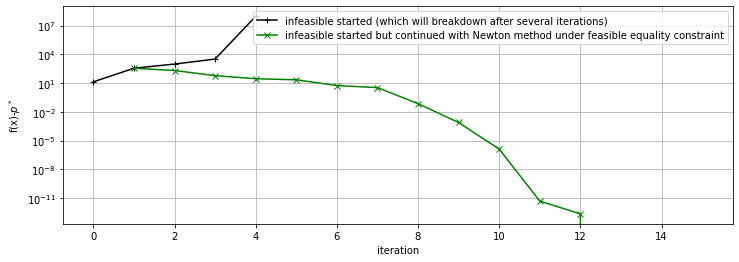

In [31]:
if __name__ == "__main__":
    solve_minimum_length_piecewise_curve_problem(n=1000, m=4, seed=3)